<a href="https://colab.research.google.com/github/camsmugereski/BU-OMDS-Capstone/blob/main/OMDS_ModC1_Week2_Smugereski_Cameron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 Jupyter Notebook – Linear Regression 2
## Regularized Regression for Credit Risk Analysis

### Project Overview

This project examines systemic banking risk by analyzing how borrower characteristics, macroeconomic conditions, and banking system indicators relate to financial risk.

For Week 2, I continue the borrower-level Credit Risk analysis from Week 1. The dependent variable is `loan_amnt`, and the goal is to examine whether regularization improves linear regression performance and helps control model complexity.

The primary question for this notebook is:

**How do Ridge, Lasso, and Elastic Net regularization affect the performance and coefficients of a linear regression model predicting loan amount?**

This analysis includes:

- Multiple linear regression as a baseline
- Ridge regression
- Lasso regression
- Elastic Net regression
- Cross-validation for regularization parameter selection
- Comparison of model performance
- Coefficient shrinkage and feature selection
- Evaluation of overfitting

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import (
    LinearRegression,
    RidgeCV,
    LassoCV,
    ElasticNetCV
)

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

pd.set_option('display.max_columns', None)

In [ ]:
uploaded = files.upload()

Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv


In [ ]:
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("File loaded:", file_name)
print("Dataset shape:", df.shape)

df.head()

File loaded: credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nSummary Statistics:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB

Missing V

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0



Summary Statistics:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


## Feature Selection

I am using `loan_amnt` as the dependent variable again so that I can compare my results with Week 1. The predictors include a mix of continuous and categorical borrower characteristics, such as income, age, employment length, interest rate, home ownership, loan intent, and loan grade.

I decided not to use `loan_percent_income` in these models. In Week 1, I found that using this variable in an interaction term resulted in an unusually high R². Since loan percent income is calculated using both income and loan amount, including it could give the model information that is too closely related to the target. Removing it should give me a more realistic idea of how well the other borrower characteristics can predict loan amount.


In [ ]:
target = 'loan_amnt'

continuous_features = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_int_rate',
    'cb_person_cred_hist_length'
]

categorical_features = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

model_columns = continuous_features + categorical_features + [target]

data = df[model_columns].copy()

print("Rows before removing missing values:", len(data))

data = data.dropna()

print("Rows after removing missing values:", len(data))

data.head()

Rows before removing missing values: 32581
Rows after removing missing values: 28638


,person_age,person_income,person_emp_length,loan_int_rate,cb_person_cred_hist_length,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file,loan_amnt
0,22,59000,123.0,16.02,3,RENT,PERSONAL,D,Y,35000
1,21,9600,5.0,11.14,2,OWN,EDUCATION,B,N,1000
2,25,9600,1.0,12.87,3,MORTGAGE,MEDICAL,C,N,5500
3,23,65500,4.0,15.23,2,RENT,MEDICAL,C,N,35000
4,24,54400,8.0,14.27,4,RENT,MEDICAL,C,Y,35000


In [ ]:
X = data[continuous_features + categorical_features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 22910
Testing observations: 5728


## Data Preprocessing

Before running the models, I standardized the continuous variables so they are on similar scales. This is especially important for Ridge, Lasso, and Elastic Net because these models apply penalties to the regression coefficients.

I also converted the categorical variables into dummy variables using one-hot encoding so they can be included in the regression models.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'continuous',
            StandardScaler(),
            continuous_features
        ),
        (
            'categorical',
            OneHotEncoder(
                drop='first',
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ]
)

## Baseline Linear Regression

I started with a regular multiple linear regression model to use as a baseline. This gives me something to compare the three regularized models against.

I used R², RMSE, and MAE to evaluate the models. R² shows how much of the variation in loan amount is explained by the model, while RMSE and MAE show how far the predictions are from the actual loan amounts.

I also compared the training and testing R² values to see if there are signs of overfitting.

In [ ]:
baseline_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regression', LinearRegression())
    ]
)

baseline_model.fit(X_train, y_train)

baseline_train_pred = baseline_model.predict(X_train)
baseline_test_pred = baseline_model.predict(X_test)

baseline_train_r2 = r2_score(
    y_train,
    baseline_train_pred
)

baseline_test_r2 = r2_score(
    y_test,
    baseline_test_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_test_pred
    )
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_test_pred
)

print("Baseline Linear Regression")
print("--------------------------")
print(f"Training R²: {baseline_train_r2:.4f}")
print(f"Testing R²:  {baseline_test_r2:.4f}")
print(f"Test RMSE:   {baseline_rmse:.2f}")
print(f"Test MAE:    {baseline_mae:.2f}")

Baseline Linear Regression
--------------------------
Training R²: 0.1112
Testing R²:  0.1418
Test RMSE:   5874.65
Test MAE:    4606.90


## Ridge Regression

The first regularized model I tested was Ridge regression. Ridge adds a penalty for large coefficients, which can help keep the model from relying too heavily on individual predictors.

Ridge usually shrinks coefficients instead of removing variables completely. I used cross-validation to choose the alpha value so that the amount of regularization was based on the data rather than choosing it manually.

In [ ]:
ridge_alphas = np.logspace(-4, 4, 100)

ridge_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'regression',
            RidgeCV(
                alphas=ridge_alphas,
                cv=5
            )
        )
    ]
)

ridge_model.fit(X_train, y_train)

ridge_train_pred = ridge_model.predict(X_train)
ridge_test_pred = ridge_model.predict(X_test)

ridge_train_r2 = r2_score(
    y_train,
    ridge_train_pred
)

ridge_test_r2 = r2_score(
    y_test,
    ridge_test_pred
)

ridge_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ridge_test_pred
    )
)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_test_pred
)

ridge_alpha = ridge_model.named_steps[
    'regression'
].alpha_

print("Ridge Regression")
print("----------------")
print(f"Best alpha: {ridge_alpha:.6f}")
print(f"Training R²: {ridge_train_r2:.4f}")
print(f"Testing R²:  {ridge_test_r2:.4f}")
print(f"Test RMSE:   {ridge_rmse:.2f}")
print(f"Test MAE:    {ridge_mae:.2f}")

Ridge Regression
----------------
Best alpha: 8302.175681
Training R²: 0.0938
Testing R²:  0.1150
Test RMSE:   5965.89
Test MAE:    4674.57


## Lasso Regression

Next, I tested Lasso regression. Lasso also penalizes large coefficients, but unlike Ridge, it can reduce some coefficients all the way to zero.

This makes Lasso useful for feature selection because variables that are not contributing much to the model can essentially be removed. I used cross-validation again to select the alpha value.

In [ ]:
lasso_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'regression',
            LassoCV(
                alphas=np.logspace(-4, 4, 100),
                cv=5,
                max_iter=50000,
                random_state=42
            )
        )
    ]
)

lasso_model.fit(X_train, y_train)

lasso_train_pred = lasso_model.predict(X_train)
lasso_test_pred = lasso_model.predict(X_test)

lasso_train_r2 = r2_score(
    y_train,
    lasso_train_pred
)

lasso_test_r2 = r2_score(
    y_test,
    lasso_test_pred
)

lasso_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lasso_test_pred
    )
)

lasso_mae = mean_absolute_error(
    y_test,
    lasso_test_pred
)

lasso_alpha = lasso_model.named_steps[
    'regression'
].alpha_

print("Lasso Regression")
print("----------------")
print(f"Best alpha: {lasso_alpha:.6f}")
print(f"Training R²: {lasso_train_r2:.4f}")
print(f"Testing R²:  {lasso_test_r2:.4f}")
print(f"Test RMSE:   {lasso_rmse:.2f}")
print(f"Test MAE:    {lasso_mae:.2f}")

Lasso Regression
----------------
Best alpha: 1.321941
Training R²: 0.1111
Testing R²:  0.1417
Test RMSE:   5875.16
Test MAE:    4608.43


## Elastic Net Regression

The last regularized model I tested was Elastic Net. Elastic Net combines parts of both Ridge and Lasso regression, so it can shrink coefficients while also reducing some of them to zero.

I wanted to see whether combining the two types of regularization would perform better than using Ridge or Lasso on their own. Cross-validation was used to choose the alpha value and the balance between the Ridge and Lasso penalties.

In [ ]:
elastic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'regression',
            ElasticNetCV(
                l1_ratio=[
                    0.1,
                    0.25,
                    0.5,
                    0.75,
                    0.9,
                    0.95
                ],
                alphas=np.logspace(-4, 4, 100),
                cv=5,
                max_iter=50000,
                random_state=42
            )
        )
    ]
)

elastic_model.fit(X_train, y_train)

elastic_train_pred = elastic_model.predict(X_train)
elastic_test_pred = elastic_model.predict(X_test)

elastic_train_r2 = r2_score(
    y_train,
    elastic_train_pred
)

elastic_test_r2 = r2_score(
    y_test,
    elastic_test_pred
)

elastic_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        elastic_test_pred
    )
)

elastic_mae = mean_absolute_error(
    y_test,
    elastic_test_pred
)

elastic_alpha = elastic_model.named_steps[
    'regression'
].alpha_

elastic_l1_ratio = elastic_model.named_steps[
    'regression'
].l1_ratio_

print("Elastic Net Regression")
print("----------------------")
print(f"Best alpha: {elastic_alpha:.6f}")
print(f"Best L1 ratio: {elastic_l1_ratio:.2f}")
print(f"Training R²: {elastic_train_r2:.4f}")
print(f"Testing R²:  {elastic_test_r2:.4f}")
print(f"Test RMSE:   {elastic_rmse:.2f}")
print(f"Test MAE:    {elastic_mae:.2f}")

Elastic Net Regression
----------------------
Best alpha: 0.911163
Best L1 ratio: 0.50
Training R²: 0.0904
Testing R²:  0.1096
Test RMSE:   5983.81
Test MAE:    4686.00


## Model Comparison

After running all four models, I compared their training R², testing R², RMSE, and MAE.

The main thing I am looking for is whether any of the regularized models perform better on the test data than regular linear regression. I also want to see whether regularization reduces the difference between training and testing performance, which could indicate better generalization to new data.

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge',
        'Lasso',
        'Elastic Net'
    ],
    'Train R²': [
        baseline_train_r2,
        ridge_train_r2,
        lasso_train_r2,
        elastic_train_r2
    ],
    'Test R²': [
        baseline_test_r2,
        ridge_test_r2,
        lasso_test_r2,
        elastic_test_r2
    ],
    'Test RMSE': [
        baseline_rmse,
        ridge_rmse,
        lasso_rmse,
        elastic_rmse
    ],
    'Test MAE': [
        baseline_mae,
        ridge_mae,
        lasso_mae,
        elastic_mae
    ]
})

results.round(4)

,Model,Train R²,Test R²,Test RMSE,Test MAE
0,Linear Regression,0.1112,0.1418,5874.6482,4606.8955
1,Ridge,0.0938,0.1150,5965.8938,4674.5730
2,Lasso,0.1111,0.1417,5875.1587,4608.4258
3,Elastic Net,0.0904,0.1096,5983.8100,4685.9968


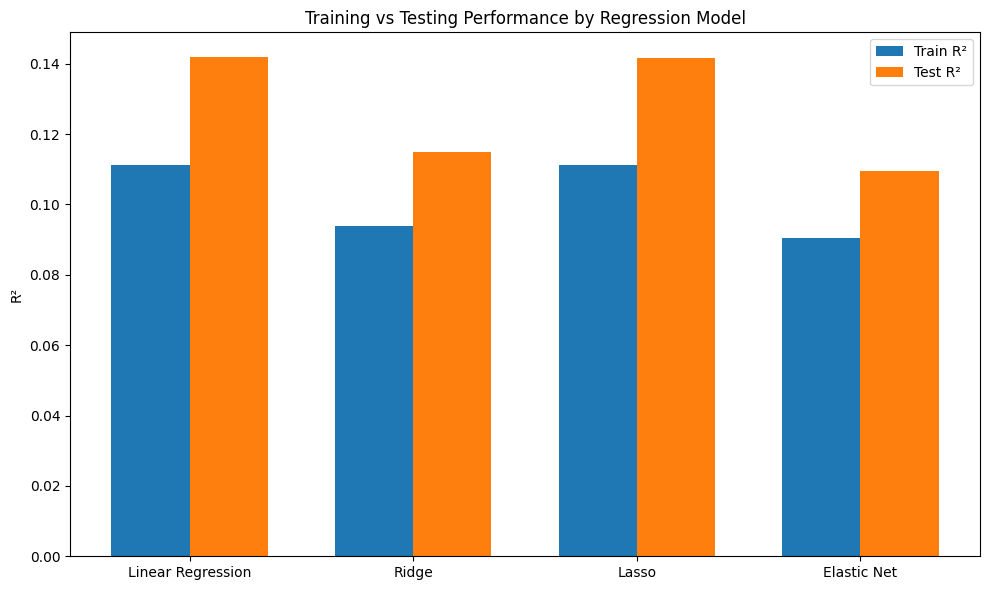

In [ ]:
plt.figure(figsize=(10, 6))

x = np.arange(len(results))
width = 0.35

plt.bar(
    x - width / 2,
    results['Train R²'],
    width,
    label='Train R²'
)

plt.bar(
    x + width / 2,
    results['Test R²'],
    width,
    label='Test R²'
)

plt.xticks(
    x,
    results['Model']
)

plt.ylabel('R²')
plt.title(
    'Training vs Testing Performance by Regression Model'
)

plt.legend()
plt.tight_layout()
plt.show()

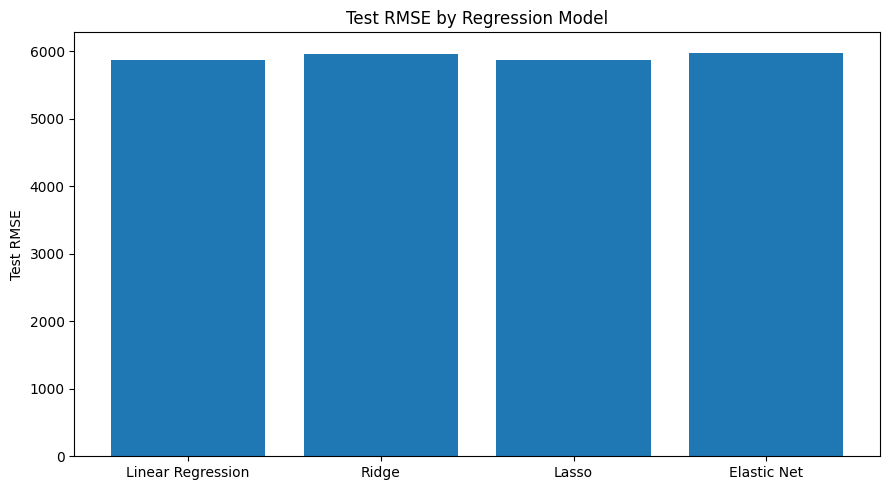

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    results['Model'],
    results['Test RMSE']
)

plt.ylabel('Test RMSE')
plt.title(
    'Test RMSE by Regression Model'
)

plt.tight_layout()
plt.show()

## Coefficient Shrinkage and Feature Selection

Another part of this analysis is looking at how regularization changes the model coefficients.

I compared the coefficients from regular linear regression with Ridge, Lasso, and Elastic Net. Ridge should generally make the coefficients smaller, while Lasso and Elastic Net may reduce some coefficients to zero.

This helps me see whether the regularized models are placing less importance on certain borrower characteristics or removing them from the model altogether.

In [ ]:
feature_names = (
    baseline_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

feature_names = [
    name.replace('continuous__', '')
        .replace('categorical__', '')
    for name in feature_names
]

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Linear': baseline_model
        .named_steps['regression']
        .coef_,
    'Ridge': ridge_model
        .named_steps['regression']
        .coef_,
    'Lasso': lasso_model
        .named_steps['regression']
        .coef_,
    'Elastic Net': elastic_model
        .named_steps['regression']
        .coef_
})

coefficient_df

,Feature,Linear,Ridge,Lasso,Elastic Net
0,person_age,-208.092477,-3.699240,-196.734262,9.544919
1,person_income,1404.380319,1083.018906,1403.837627,1017.395947
2,person_emp_length,461.175976,410.474889,459.979472,391.350823
3,loan_int_rate,682.057922,719.564701,834.989868,664.282207
4,cb_person_cred_hist_length,176.144499,44.169933,165.144693,41.376277
5,person_home_ownership_OTHER,266.958433,8.827613,0.000000,6.489742
6,person_home_ownership_OWN,-1105.298573,-121.527426,-1089.681493,-95.801233
7,person_home_ownership_RENT,-1203.163106,-463.969506,-1198.806639,-407.394506
8,loan_intent_EDUCATION,33.904707,-4.056802,31.015962,-3.369067
9,loan_intent_HOMEIMPROVEMENT,375.729628,106.135199,371.264515,90.827785


In [ ]:
coefficient_df[
    'Linear Absolute'
] = coefficient_df['Linear'].abs()

coefficient_df = coefficient_df.sort_values(
    'Linear Absolute',
    ascending=False
)

display(
    coefficient_df[
        [
            'Feature',
            'Linear',
            'Ridge',
            'Lasso',
            'Elastic Net'
        ]
    ].round(3)
)

,Feature,Linear,Ridge,Lasso,Elastic Net
18,loan_grade_G,6035.875,33.766,4795.433,26.726
17,loan_grade_F,4411.022,77.294,3666.515,62.957
16,loan_grade_E,2475.671,144.230,1938.082,121.622
1,person_income,1404.380,1083.019,1403.838,1017.396
7,person_home_ownership_RENT,-1203.163,-463.970,-1198.807,-407.395
6,person_home_ownership_OWN,-1105.299,-121.527,-1089.681,-95.801
15,loan_grade_D,926.359,77.690,498.940,76.823
13,loan_grade_B,909.721,221.548,715.274,194.451
3,loan_int_rate,682.058,719.565,834.990,664.282
2,person_emp_length,461.176,410.475,459.979,391.351


In [ ]:
lasso_zero = np.sum(
    np.isclose(
        coefficient_df['Lasso'],
        0
    )
)

elastic_zero = np.sum(
    np.isclose(
        coefficient_df['Elastic Net'],
        0
    )
)

print(
    "Total predictors after encoding:",
    len(coefficient_df)
)

print(
    "Coefficients reduced to zero by Lasso:",
    lasso_zero
)

print(
    "Coefficients reduced to zero by Elastic Net:",
    elastic_zero
)

Total predictors after encoding: 20
Coefficients reduced to zero by Lasso: 2
Coefficients reduced to zero by Elastic Net: 1


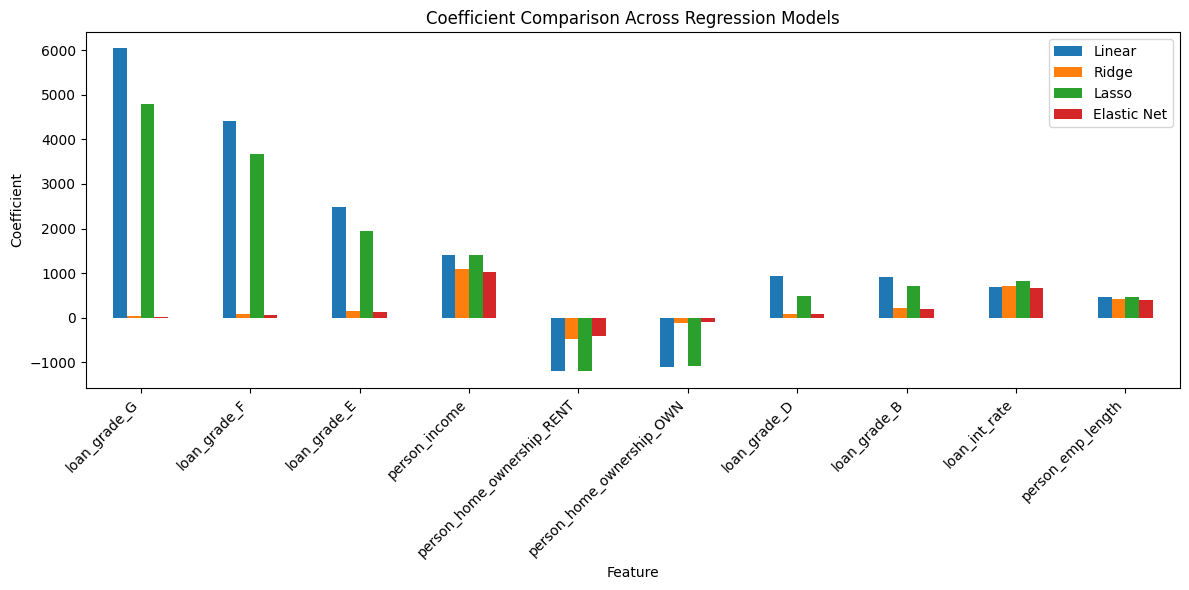

In [ ]:
top_coefficients = (
    coefficient_df
    .head(10)
    .copy()
)

plot_df = top_coefficients.set_index(
    'Feature'
)[
    [
        'Linear',
        'Ridge',
        'Lasso',
        'Elastic Net'
    ]
]

plot_df.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.ylabel('Coefficient')
plt.title(
    'Coefficient Comparison Across Regression Models'
)

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()
plt.show()

## Overfitting and Regularization

One reason for using regularization is to help prevent overfitting. To look for this, I compared the training and testing R² for each model.

If a model performs much better on the training data than the test data, that could be a sign that it is fitting the training data too closely. I want to see whether Ridge, Lasso, or Elastic Net reduce this gap while still maintaining good performance on the test data.

In [ ]:
results['R² Gap'] = (
    results['Train R²'] -
    results['Test R²']
).abs()

display(
    results.sort_values(
        'Test R²',
        ascending=False
    ).round(4)
)

,Model,Train R²,Test R²,Test RMSE,Test MAE,R² Gap
0,Linear Regression,0.1112,0.1418,5874.6482,4606.8955,0.0306
2,Lasso,0.1111,0.1417,5875.1587,4608.4258,0.0305
1,Ridge,0.0938,0.1150,5965.8938,4674.5730,0.0212
3,Elastic Net,0.0904,0.1096,5983.8100,4685.9968,0.0192


In [ ]:
best_r2_model = results.loc[
    results['Test R²'].idxmax(),
    'Model'
]

best_rmse_model = results.loc[
    results['Test RMSE'].idxmin(),
    'Model'
]

smallest_gap_model = results.loc[
    results['R² Gap'].idxmin(),
    'Model'
]

print("MODEL SUMMARY")
print("=" * 60)

print(
    "Highest Test R²:",
    best_r2_model
)

print(
    "Lowest Test RMSE:",
    best_rmse_model
)

print(
    "Smallest Train/Test R² Gap:",
    smallest_gap_model
)

print("\nRegularization Parameters")
print("-" * 60)

print(
    f"Ridge alpha: {ridge_alpha:.6f}"
)

print(
    f"Lasso alpha: {lasso_alpha:.6f}"
)

print(
    f"Elastic Net alpha: {elastic_alpha:.6f}"
)

print(
    f"Elastic Net L1 ratio: {elastic_l1_ratio:.2f}"
)

print("\nFeature Selection")
print("-" * 60)

print(
    f"Lasso zero coefficients: {lasso_zero}"
)

print(
    f"Elastic Net zero coefficients: {elastic_zero}"
)

MODEL SUMMARY
Highest Test R²: Linear Regression
Lowest Test RMSE: Linear Regression
Smallest Train/Test R² Gap: Elastic Net

Regularization Parameters
------------------------------------------------------------
Ridge alpha: 8302.175681
Lasso alpha: 1.321941
Elastic Net alpha: 0.911163
Elastic Net L1 ratio: 0.50

Feature Selection
------------------------------------------------------------
Lasso zero coefficients: 2
Elastic Net zero coefficients: 1


## Week 2 Conclusions

For Week 2, I compared regular linear regression with Ridge, Lasso, and Elastic Net to see if regularization could improve the prediction of loan amount. Overall, regularization did not improve the model's performance, but it did show how the different methods affect coefficients and feature selection.

### Baseline Linear Regression

The baseline linear regression had a training R² of 0.1112 and a test R² of 0.1418. The test RMSE was 5,874.65 and the MAE was 4,606.90. This means that the model only explained about 14% of the variation in loan amount in the test data.

The performance was much lower than some of the models from Week 1, which makes sense because I removed `loan_percent_income` due to the target leakage concern I found in that analysis.

### Ridge Regression

Ridge regression selected an alpha of 8302.175681 through cross-validation. It had a test R² of 0.1150, an RMSE of 5,965.89, and an MAE of 4,674.57.

Ridge did not improve prediction performance compared with the baseline model. However, I could see that it substantially reduced the size of many of the coefficients. For example, the coefficient for loan grade G decreased from 6,035.88 in the regular linear model to only 33.77 with Ridge.

### Lasso Regression

Lasso selected an alpha of 1.321941 and performed almost exactly the same as the baseline model. Its test R² was 0.1417, with an RMSE of 5,875.16 and an MAE of 4,608.43.

Lasso also reduced two of the 20 predictor coefficients to zero. This shows the feature selection aspect of Lasso, although removing those predictors did not improve the model's overall prediction accuracy.

### Elastic Net Regression

Elastic Net selected an alpha of 0.911163 and an L1 ratio of 0.50. It reduced one coefficient to zero and had a test R² of 0.1096, an RMSE of 5,983.81, and an MAE of 4,686.00.

Elastic Net had the lowest predictive performance of the four models. Combining the Ridge and Lasso penalties did not improve the model for this dataset.

### Overfitting

I compared the training and testing R² values to look for signs of overfitting. Elastic Net had the smallest difference between training and testing R² at 0.0192, followed by Ridge at 0.0212. The baseline model had a gap of 0.0306 and Lasso had a gap of 0.0305.

Even though Elastic Net had the smallest gap, it also had the lowest test R². Because none of the models had a large difference between their training and testing results, I do not see strong evidence that overfitting was a major issue in this analysis.

### Overall Conclusion

The regular linear regression had the highest test R² and lowest RMSE, making it the best-performing model in this analysis. Lasso was extremely close to the baseline model, while Ridge and Elastic Net performed slightly worse.

One thing I found interesting was that regularization clearly changed the coefficients even though it did not improve prediction accuracy. Lasso removed two predictors completely, while Ridge greatly reduced some of the largest coefficients. This shows that regularization can simplify or stabilize a model without necessarily making its predictions better.

Compared with Week 1, removing `loan_percent_income` also resulted in much lower R² values. I think this supports my concern that the unusually high performance in the Week 1 interaction model was related to target leakage. The Week 2 results give me a more realistic picture of how much of the variation in loan amount can actually be explained by the remaining borrower characteristics.